CUSTOMER BEHAVIOUR ANALYSIS USING PYTHON

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("customer_behavior.csv")

Question 1

In [3]:
purchase = df["PurchaseAmount"].dropna()

print("Mean: ",purchase.mean())
print("Median: ",purchase.median())
print("Mode: ",purchase.mode().tolist()) 

Mean:  1003.9506701030928
Median:  998.0799999999999
Mode:  [0.0]


Question 2

Q1:  673.6424999999999
Q3:  1327.0775
IQR:  653.4350000000002
Number of Outliers:  4382


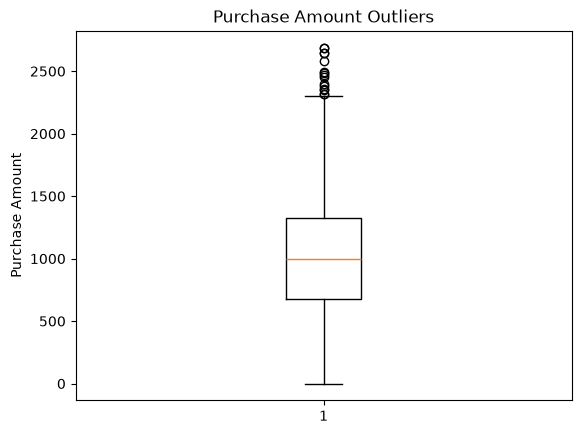

In [6]:
Q1 = purchase.quantile(0.25)
Q3 = purchase.quantile(0.75) 
IQR = Q3-Q1
lower_bound = Q1-1.5*IQR
upper_bound = Q3-1.5*IQR
outliers = purchase[(purchase < lower_bound)|(purchase > upper_bound)]
print("Q1: ",Q1)
print("Q3: ",Q3)
print("IQR: ",IQR)
print("Number of Outliers: ",len(outliers))

plt.boxplot(purchase)
plt.title("Purchase Amount Outliers")
plt.ylabel("Purchase Amount")
plt.show()

Question 3

Skewness:  0.10609189374631554
Kurtosis:  -0.2615105545319705


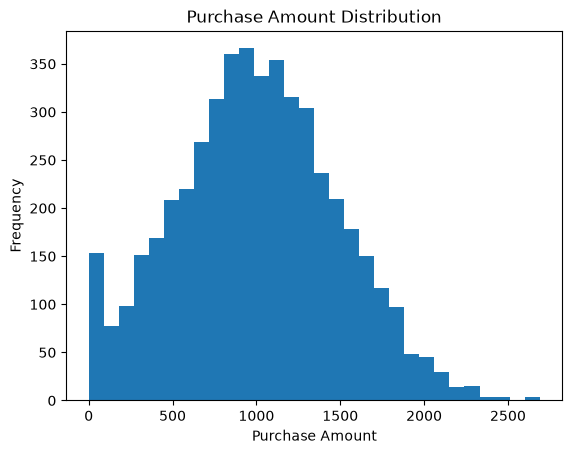

In [8]:
print("Skewness: ",purchase.skew())
print("Kurtosis: ",purchase.kurt())

plt.hist(purchase, bins=30)
plt.title("Purchase Amount Distribution")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.show()

Question 4

Male Average:  1019.1766093880973
Female Average:  987.8720464135021
T-statistic:  2.234798912073049
P-value:  0.025476849797238164
Significant difference exists


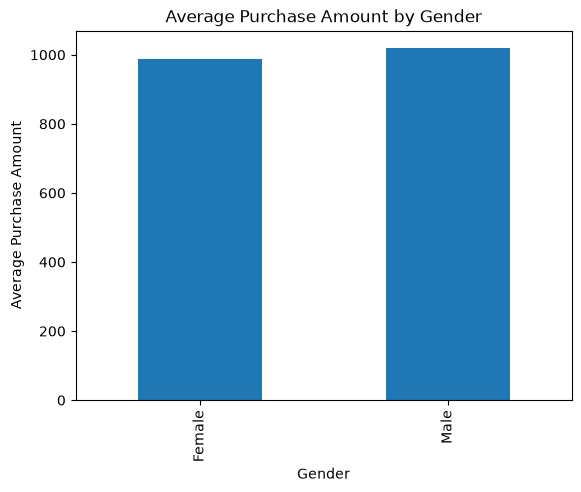

In [10]:
gender_data = df.dropna(subset=["Gender","PurchaseAmount"])
male = gender_data[gender_data["Gender"] == "Male"]["PurchaseAmount"]
female = gender_data[gender_data["Gender"] == "Female"]["PurchaseAmount"]

print("Male Average: ",male.mean())
print("Female Average: ",female.mean())

t_stat, p_value = stats.ttest_ind(male, female, equal_var=False)
print("T-statistic: ",t_stat)
print("P-value: ",p_value)

if p_value < 0.05:
    print("Significant difference exists")
else:
    print("No significant difference")

gender_data.groupby("Gender")["PurchaseAmount"].mean().plot(kind="bar")
plt.title("Average Purchase Amount by Gender")
plt.ylabel("Average Purchase Amount")
plt.show()


Question 5

In [12]:
churn_data = df.dropna(subset=["ProductCategory", "Churn"])

contingency_table = pd.crosstab(churn_data["ProductCategory"],churn_data["Churn"])

print(contingency_table)

chi2, p_value, dof, expected = ( stats.chi2_contingency(contingency_table))

print("Chi-square:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

if p_value < 0.05:
    print("Significant relationship exists")
else:
    print("No significant relationship")

Churn             No  Yes
ProductCategory          
Electronics      785  541
Fashion          839  607
Grocery          855  604
Chi-square: 0.3960436652673918
P-value: 0.8203519424988512
Degrees of Freedom: 2
No significant relationship


Question 6


Region
East     1009.946017
North    1013.017952
South     997.603877
West      995.247327
Name: PurchaseAmount, dtype: float64
F-statistic: 0.38966786354806704
P-value: 0.7604528027310101
No significant difference across regions


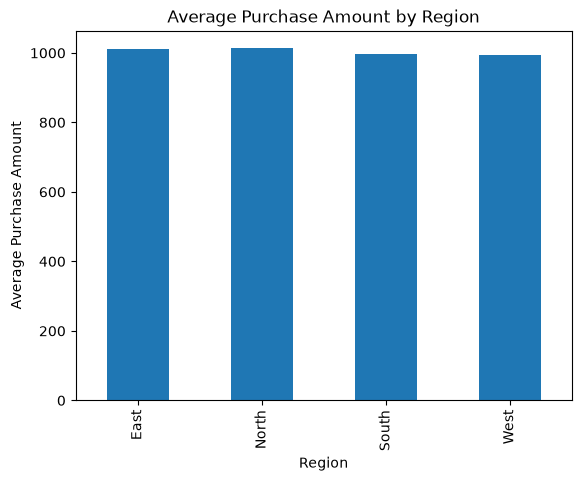

In [13]:
region_data = df.dropna(subset=["Region", "PurchaseAmount"])

print(region_data.groupby("Region")["PurchaseAmount"].mean())

region_groups = [group["PurchaseAmount"].values for _, group in region_data.groupby("Region")]

f_stat, p_value = stats.f_oneway(*region_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Significant difference exists across regions")
else:
    print("No significant difference across regions")

region_data.groupby("Region")["PurchaseAmount"].mean().plot(kind="bar")

plt.title("Average Purchase Amount by Region")
plt.ylabel("Average Purchase Amount")
plt.show()

Question 7

Campaign A Average: 1011.9455872340425
Campaign B Average: 994.3399654874893
T-statistic: 1.2430861943551852
P-value: 0.21389858277292217
Difference is not statistically significant


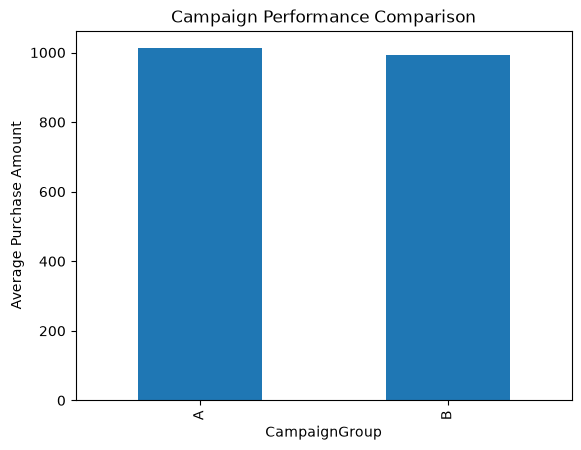

In [14]:
campaign_data = df.dropna(subset=["CampaignGroup", "PurchaseAmount"])
campaign_A = campaign_data[campaign_data["CampaignGroup"] == "A"]["PurchaseAmount"]
campaign_B = campaign_data[campaign_data["CampaignGroup"] == "B"]["PurchaseAmount"]

print("Campaign A Average:", campaign_A.mean())
print("Campaign B Average:", campaign_B.mean())

t_stat, p_value = stats.ttest_ind(campaign_A, campaign_B, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Difference is statistically significant")
else:
    print("Difference is not statistically significant")

campaign_data.groupby("CampaignGroup")["PurchaseAmount"].mean().plot(kind="bar")

plt.title("Campaign Performance Comparison")
plt.ylabel("Average Purchase Amount")
plt.show()

Question 8

Skewness: 0.10609189374631554
Kurtosis: -0.2615105545319705
Normality Test Statistic: 27.251556517359987
P-value: 1.208925924000244e-06
PurchaseAmount does not follow a normal distribution


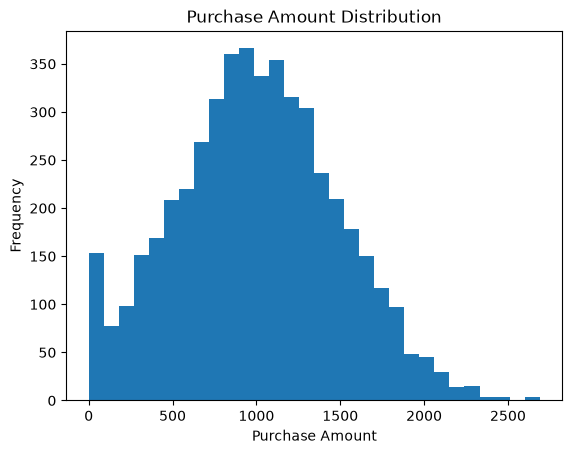

In [15]:
purchase = df["PurchaseAmount"].dropna()

print("Skewness:", purchase.skew())
print("Kurtosis:", purchase.kurt())

statistic, p_value = stats.normaltest(purchase)

print("Normality Test Statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("PurchaseAmount does not follow a normal distribution")
else:
    print("Insufficient evidence to reject normality")

plt.hist(purchase, bins=30)
plt.title("Purchase Amount Distribution")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.show()

Question 9

Original Mean: 1003.9506701030928
Mean of Sample Means: 1002.79177


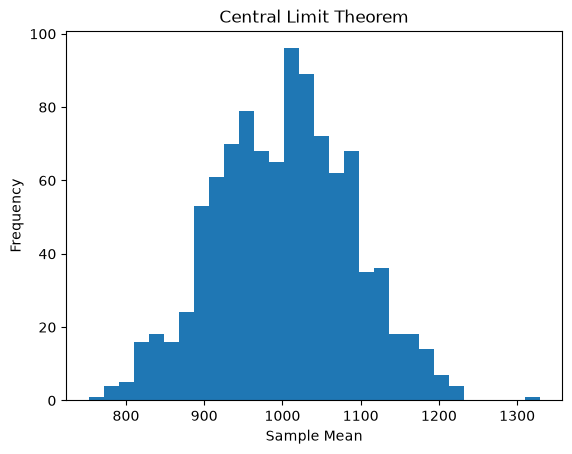

In [16]:
np.random.seed(42)
purchase = df["PurchaseAmount"].dropna()
sample_means = []

for i in range(1000):
    sample = purchase.sample(n=30,replace=True)
    sample_means.append(sample.mean())

print("Original Mean:", purchase.mean())
print("Mean of Sample Means:", np.mean(sample_means))

plt.hist(sample_means, bins=30)
plt.title("Central Limit Theorem")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.show()

Question 10

In [17]:
purchase = df["PurchaseAmount"].dropna()
n = len(purchase)
mean = purchase.mean()
standard_error = stats.sem(purchase)
confidence_interval = stats.t.interval(confidence = 0.95, df = n - 1, loc = mean, scale = standard_error)

print("Sample Size:", n)
print("Mean Purchase Amount:", mean)
print("95% Confidence Interval:", confidence_interval)

Sample Size: 4850
Mean Purchase Amount: 1003.9506701030928
95% Confidence Interval: (np.float64(990.3789594609216), np.float64(1017.522380745264))
